# Paper tables and figures

Reproduces every table and figure of the paper from the saved model outputs, without retraining:
- **Classical models** (logistic regression, random forest, XGBoost) are refit here from the cached similarity features (deterministic, about a minute; the first run builds the feature cache, a few minutes).
- **Neural models** are read from `predictions/<run>/probs_{val,test}_seed_{s}.npy`, written by each family's training code. A prediction is probability ≥ 0.5. Every neural model has three seeds, reported as min–max.
- **Table B1** compares with the earlier version of the study; its v1 numbers come from `results/v1_missing_number_matches.csv` (the v1 outputs are only in the git history).

Pair types use the paper's names; the code names (`neg_type`) appear only in Table 1.

| Section | Paper |
|---|---|
| 1 | Table 1 (pair types), Figure 1 (pipeline), Table 2 (features) |
| 2 | Tables 3, 4 (classical, sentinel vs zero-fill), A1, A2 (random-forest importance) |
| 3 | Tables 5, 6, 7 (siamese BiLSTM) |
| 4 | Tables 8, 9, 10, 11 (ESIM) |
| 5 | Tables 12, 13, 14, 15 and Figure 3 (DistilBERT, every kept model) |
| 6 | Table B1 (earlier version vs this one) |
| 7 | Numbers quoted in the Discussion |

## 0. Setup

In [1]:
import os
import sys
sys.path.append("..")   # repository root -> lets us import helpers/, tools/ and the model packages

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from helpers.pairs import load_pairs, add_number_street
from helpers.paths import FEATURES, PREDICTIONS, probs_path
from helpers.features import get_processed_dfs
from classical.models import run_against_models

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

DATASET = "overture_case2s"
THRESHOLD = 0.5
SEEDS = [0, 1, 2]
FIGURES = "figures"   # results/figures/

pairs = {split: load_pairs(DATASET, split) for split in ["train", "val", "test"]}
df = {split: add_number_street(d) for split, (d, _) in pairs.items()}
y = {split: lab.values for split, (_, lab) in pairs.items()}
test = df["test"]

In [2]:
# One mask per pair type (the columns of the per-type tables); "found" for matches, "rejected" for non-matches
PAIR_TYPES = {
    "Identical found":           lambda d, l: (l == 1) & (d["address_a"] == d["address_b"]).values,
    "Non-identical found":       lambda d, l: (l == 1) & (d["address_a"] != d["address_b"]).values,
    "Different number rejected": lambda d, l: (d["neg_type"] == "case1").values,
    "Look-alike rejected":       lambda d, l: (d["neg_type"] == "case2s").values,
    "Random rejected":           lambda d, l: (d["neg_type"] == "case3").values,
}
AUC_COL = "AUC, non-identical vs look-alike"
masks = {split: {name: f(df[split], y[split]) for name, f in PAIR_TYPES.items()} for split in df}
one_missing = {split: (d["number_a"].notna() != d["number_b"].notna()).values for split, d in df.items()}
n_row = lambda split: {name: f"{int(m.sum()):,}" for name, m in masks[split].items()}


def pct_correct(preds, split, mask):
    return 100 * (preds[mask] == y[split][mask]).mean()


def auc_vs(probs, pos_mask, neg_mask):
    """AUC: chance that a random pair of pos_mask scores above a random pair of neg_mask."""
    return roc_auc_score(np.r_[np.ones(pos_mask.sum()), np.zeros(neg_mask.sum())], np.r_[probs[pos_mask], probs[neg_mask]])


def type_row(probs, split):
    """% correct per pair type + AUC non-identical vs look-alike, for one run's probabilities."""
    preds = (probs >= THRESHOLD).astype(int)
    row = {name: pct_correct(preds, split, m) for name, m in masks[split].items()}
    row[AUC_COL] = auc_vs(probs, masks[split]["Non-identical found"], masks[split]["Look-alike rejected"])
    return row


def load_probs(run, split, seed):
    return np.load(probs_path(run, split, seed)).ravel()


def seeds_of(run, split):
    return [load_probs(run, split, s) for s in SEEDS]


def fmt_range(values, digits=1):
    """Min–max over seeds, as in the paper ('a–b', or one number when they agree)."""
    lo, hi = f"{min(values):.{digits}f}", f"{max(values):.{digits}f}"
    return lo if lo == hi else f"{lo}–{hi}"


def range_table(rows_per_model, digits=None):
    """{model: [row per seed]} -> one formatted row per model (min–max over seeds per column; AUC to 3 decimals)."""
    out = {}
    for model, rows in rows_per_model.items():
        frame = pd.DataFrame(rows)
        out[model] = {col: fmt_range(frame[col], digits if digits is not None else 3 if col.startswith("AUC") else 1)
                      for col in frame.columns}
    return pd.DataFrame(out).T


def type_table(probs_per_model, split="test", with_n=False):
    """{model: [probs per seed]} -> the paper's per-type table (Tables 5, 7, 11, 12, 15)."""
    table = range_table({m: [type_row(p, split) for p in probs] for m, probs in probs_per_model.items()})
    if with_n:
        table = pd.concat([pd.DataFrame({**n_row(split), AUC_COL: ""}, index=["n (pairs)"]), table])
    return table

## 1. Data: Table 1, Figure 1, Table 2

### Table 1: pair types, with the name used in the code and test-set counts

In [3]:
TABLE1 = [   # type, code name, label, example, how built, test mask
    ("Positive, identical", "case0", "match", "7 BACKUS AVE / 7 BACKUS AVE",
     "Overture ↔ Foursquare bridge match, strings equal", masks["test"]["Identical found"]),
    ("Positive, non-identical", "case0", "match", "12 ELM ST / 12 ELM STREET",
     "Bridge match, strings differ", masks["test"]["Non-identical found"]),
    ("Different number", "case1", "non-match", "12 ELM ST / 14 ELM ST",
     "Same ZIP and street, both sides have a number, numbers differ; ≤ 5 partners per place", None),
    ("Real look-alike street", "case2", "non-match", "100 N MAIN ST / 100 S MAIN ST",
     "Real places: same ZIP and number, street JW > 0.8, > 500 m apart", None),
    ("Look-alike street", "case2s", "non-match", "431 HALLETT ST / 431 HARRIET ST",
     "Real address, street swapped for a look-alike street in the same ZIP (JW > 0.8)", None),
    ("Random", "case3", "non-match", "random", "Two random addresses from the same split; fills the 1:9 ratio", None),
]
table1 = pd.DataFrame([{"Type": t, "Code name": c, "Label": l, "Example": e, "How built": h,
                        "Test n": f"{int((m if m is not None else (test['neg_type'] == c).values).sum()):,}"}
                       for t, c, l, e, h, m in TABLE1]).set_index("Type")
display(table1)

# Building Data: different-number pairs whose side B has no parsed house number (a bare number such as "43")
case1_one_missing = one_missing["test"] & (test["neg_type"] == "case1").values
print("different-number test pairs with a number on one side only:", int(case1_one_missing.sum()))
print(test.loc[case1_one_missing, ["address_a", "address_b"]].head(3).to_string())

,Code name,Label,Example,How built,Test n
Type,,,,,
"Positive, identical",case0,match,7 BACKUS AVE / 7 BACKUS AVE,"Overture ↔ Foursquare bridge match, strings equal","3,543"
"Positive, non-identical",case0,match,12 ELM ST / 12 ELM STREET,"Bridge match, strings differ",843
Different number,case1,non-match,12 ELM ST / 14 ELM ST,"Same ZIP and street, both sides have a number,...","14,379"
Real look-alike street,case2,non-match,100 N MAIN ST / 100 S MAIN ST,"Real places: same ZIP and number, street JW > ...",15
Look-alike street,case2s,non-match,431 HALLETT ST / 431 HARRIET ST,"Real address, street swapped for a look-alike ...","1,053"
Random,case3,non-match,random,Two random addresses from the same split; fill...,"24,019"


different-number test pairs with a number on one side only: 9
        address_a address_b
9746   92 WALL ST        43
12840  52 WALL ST        43
13900  56 WALL ST        43


### Figure 1: the data pipeline (`tools/figure_pipeline.py`)

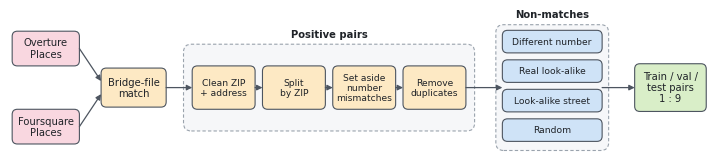

In [4]:
from tools.figure_pipeline import draw
import matplotlib.pyplot as plt

draw(FIGURES)   # -> results/figures/figure1_pipeline.{pdf,png}
plt.show()

### Table 2: the 23 features (`helpers/features.py`)
Which metric is computed on which component, read from the feature columns. Token-overlap metrics use character bigrams for street and ZIP, single characters for house numbers (see `helpers/features.py`).

In [5]:
os.makedirs(FEATURES, exist_ok=True)
X, X_zero = {}, {}
X["train"], X["val"], X["test"] = get_processed_dfs([[df[s], f"{FEATURES}/{s}.parquet"] for s in ["train", "val", "test"]])
X_zero["train"], X_zero["val"], X_zero["test"] = get_processed_dfs(
    [[df[s], f"{FEATURES}/{s}_missing_as_zero.parquet"] for s in ["train", "val", "test"]], missing_number_as_zero=True)

COMPONENT = lambda f: ("Flag" if f == "number_missing" else "House number" if "address" in f
                       else "Street" if "street" in f else "ZIP")
METRIC = {"lv": "Levenshtein", "jw": "Jaro-Winkler", "hm": "Hamming", "jaccard": "Jaccard", "cosine": "Cosine",
          "tversky": "Tversky", "sorenson": "Sørensen–Dice", "overlap": "Overlap", "number": "number_missing"}
features = pd.DataFrame({"Component": [COMPONENT(f) for f in X["train"].columns],
                         "Metric": [METRIC[f.split("_")[0]] for f in X["train"].columns]}, index=X["train"].columns)
table2 = (features.assign(v="✓").pivot(index="Metric", columns="Component", values="v").fillna("")
          [["Street", "House number", "ZIP", "Flag"]])
print("features per component:", features["Component"].value_counts().to_dict(), "| total:", len(features))
table2

features per component: {'ZIP': 8, 'Street': 7, 'House number': 7, 'Flag': 1} | total: 23


Component,Street,House number,ZIP,Flag
Metric,,,,
Cosine,✓,✓,✓,
Hamming,,,✓,
Jaccard,✓,✓,✓,
Jaro-Winkler,✓,✓,✓,
Levenshtein,✓,✓,✓,
Overlap,✓,✓,✓,
Sørensen–Dice,✓,✓,✓,
Tversky,✓,✓,✓,
number_missing,,,,✓


## 2. Classical models
Models: `classical/models.py`, library defaults (random forest and XGBoost with `random_state=0`), fit on the train split. **Sentinel** = `missing_number_as_zero=False` (house-number similarities −1 and the `number_missing` flag when one side has no number), **zero-fill** = `True`. The random forest's spread over five seeds quoted in Experimental Setup (AUC 0.921–0.924) comes from `tools/classical_seeds.py`.

In [6]:
ret, fitted = run_against_models(X["train"], y["train"], X["val"], X["test"], return_models=True)
ret_zero, fitted_zero = run_against_models(X_zero["train"], y["train"], X_zero["val"], X_zero["test"], return_models=True)
SHORT = {"LogisticRegression": "LogReg", "RandomForestClassifier": "RF", "XGBClassifier": "XGB"}
classical = {f"{SHORT[m]} {setting}": r[m] for m in SHORT for setting, r in [("sentinel", ret), ("zero-fill", ret_zero)]}
xgb = {split: classical["XGB sentinel"][split][1] for split in ["val", "test"]}   # the reference tree model
rf = {split: classical["RF sentinel"][split][1] for split in ["val", "test"]}

### Table 3: classical models per pair type, % correct, and AUC: sentinel vs zero-fill (test)

In [7]:
ROWS3 = {"Identical found": "Matches, identical (found)", "Non-identical found": "Matches, non-identical (found)",
         "Different number rejected": "Different number (rejected)", "Look-alike rejected": "Look-alike street (rejected)",
         "Random rejected": "Random (rejected)", AUC_COL: "AUC, non-identical vs look-alike"}
table3 = pd.DataFrame({name: type_row(r["test"][1], "test") for name, r in classical.items()})
table3 = table3.apply(lambda col: [f"{v:.3f}" if k == AUC_COL else f"{v:.1f}" for k, v in col.items()])
table3.insert(0, "n", [n_row("test")[k] if k in n_row("test") else "" for k in table3.index])
table3.rename(index=ROWS3)

,n,LogReg sentinel,LogReg zero-fill,RF sentinel,RF zero-fill,XGB sentinel,XGB zero-fill
"Matches, identical (found)","3,543",99.8,99.9,100.0,100.0,100.0,100.0
"Matches, non-identical (found)",843,60.1,45.0,84.0,69.0,83.6,70.0
Different number (rejected),"14,379",99.9,100.0,100.0,99.9,100.0,100.0
Look-alike street (rejected),"1,053",77.7,73.0,88.4,88.8,87.0,85.9
Random (rejected),"24,019",100.0,100.0,99.9,99.9,99.9,99.9
"AUC, non-identical vs look-alike",,0.776,0.624,0.924,0.863,0.920,0.856


### Table 4: pairs where exactly one side has a house number, split by label, % correct (test)

In [8]:
GROUPS4 = {"Matches (found)": "case0", "Different-number non-matches (rejected)": "case1", "Random non-matches (rejected)": "case3"}
group4 = {g: one_missing["test"] & (test["neg_type"] == t).values for g, t in GROUPS4.items()}
table4 = pd.DataFrame({name: {g: pct_correct(r["test"][0], "test", m) for g, m in group4.items()}
                       for name, r in classical.items()}).round(1)
table4.insert(0, "n", [int(m.sum()) for m in group4.values()])
table4

,n,LogReg sentinel,LogReg zero-fill,RF sentinel,RF zero-fill,XGB sentinel,XGB zero-fill
Matches (found),164,76.2,0.6,96.3,20.7,94.5,20.1
Different-number non-matches (rejected),9,0.0,100.0,100.0,88.9,100.0,100.0
Random non-matches (rejected),999,99.1,100.0,96.9,99.5,96.7,99.6


### Tables A1, A2: random-forest feature importance (mean impurity decrease, sums to 1), sentinel vs zero-fill
A1 sums the unrounded per-feature importances of A2.

In [9]:
importance = pd.DataFrame({
    setting: pd.Series(f["RandomForestClassifier"].feature_importances_, index=f["RandomForestClassifier"].feature_names_in_)
    for setting, f in [("RF sentinel", fitted), ("RF zero-fill", fitted_zero)]
})
tableA2 = importance.join(features)
order = {"House number": 0, "Street": 1, "ZIP": 2, "Flag": 3}
tableA2 = tableA2.sort_values(["Component", "RF sentinel"], key=lambda c: c.map(order) if c.name == "Component" else -c)
tableA1 = tableA2.groupby("Component", sort=False)[["RF sentinel", "RF zero-fill"]].sum(min_count=1)
tableA1.index = [f"{c} ({n})" if c != "Flag" else "number_missing flag" for c, n in
                 tableA2.groupby("Component", sort=False).size().items()]
display(tableA1.round(3))
tableA2.set_index(["Component", "Metric"])[["RF sentinel", "RF zero-fill"]].round(3)

,RF sentinel,RF zero-fill
House number (7),0.718,0.728
Street (7),0.243,0.255
ZIP (8),0.037,0.017
number_missing flag,0.002,NaN


RF sentinel  RF zero-fill
Component    Metric                                   
House number Levenshtein           0.181         0.187
             Jaro-Winkler          0.172         0.135
             Sørensen–Dice         0.083         0.100
             Jaccard               0.081         0.100
             Cosine                0.081         0.109
             Tversky               0.079         0.084
             Overlap               0.040         0.013
Street       Jaro-Winkler          0.064         0.055
             Overlap               0.063         0.066
             Levenshtein           0.032         0.055
             Cosine                0.024         0.020
             Sørensen–Dice         0.024         0.021
             Tversky               0.019         0.016
             Jaccard               0.017         0.022
ZIP          Cosine                0.007         0.001
             Hamming               0.006         0.001
             Sørensen–Dice         0.005         0.002
             Overlap               0.005         0.002
             Jaccard               0.004         0.002
             Tversky               0.004         0.006
             Levenshtein           0.004         0.002
             Jaro-Winkler          0.003         0.002
Flag         number_missing        0.002           NaN

In [10]:
# Caption of Table A1: XGBoost's gain importance concentrates on one feature per correlated group
pd.Series(fitted["XGBClassifier"].feature_importances_, index=features["Component"] + ", " + features["Metric"]
          ).sort_values(ascending=False).head(3).round(2)

House number, Jaro-Winkler    0.82
ZIP, Jaccard                  0.06
Street, Overlap               0.05
dtype: float32

## 3. Siamese BiLSTM
Runs `siamese_mean`, `siamese_max`, seeds 0–2 (`siamese/train.ipynb` for seed 0, `siamese/train_seeds.py` for seeds 1 and 2).

In [11]:
siamese = {pooling: {split: seeds_of(f"siamese_{pooling}", split) for split in ["val", "test"]} for pooling in ["mean", "max"]}

### Table 5: siamese BiLSTM by pooling (test, %, min–max over three seeds)

In [12]:
type_table({"Mean": siamese["mean"]["test"], "Max": siamese["max"]["test"]}, with_n=True)

,Identical found,Non-identical found,Different number rejected,Look-alike rejected,Random rejected,"AUC, non-identical vs look-alike"
n (pairs),"3,543",843,"14,379","1,053","24,019",
Mean,100.0,87.0–89.3,99.9–100.0,69.8–73.1,99.5–99.8,0.878–0.893
Max,100.0,84.2–85.3,99.9–100.0,74.9–78.0,99.8,0.873–0.885


In [13]:
# Text under Table 5: the trade-off holds on every seed (mean finds more non-identical matches, max rejects more look-alikes)
pd.DataFrame({(p, s): type_row(probs, "test") for p in ["mean", "max"] for s, probs in zip(SEEDS, siamese[p]["test"])}
             ).T[["Non-identical found", "Look-alike rejected", AUC_COL]].round(3)

Non-identical found  Look-alike rejected  AUC, non-identical vs look-alike
mean 0               86.951               73.029                             0.878
     1               87.189               73.124                             0.887
     2               89.324               69.801                             0.893
max  0               84.223               75.214                             0.876
     1               84.579               74.929                             0.873
     2               85.291               77.968                             0.885

### Table 6: siamese BiLSTM by pooling, matches where exactly one side has a house number (test, min–max over three seeds)

In [14]:
m_match = {s: one_missing[s] & (df[s]["neg_type"] == "case0").values for s in ["val", "test"]}
lookalike = {s: masks[s]["Look-alike rejected"] for s in ["val", "test"]}


def missing_row(probs, split="test"):
    return {"Matches found (%)": pct_correct((probs >= THRESHOLD).astype(int), split, m_match[split]),
            "AUC, matches vs look-alike streets": auc_vs(probs, m_match[split], lookalike[split])}


print(f"n: {int(m_match['test'].sum())} matches / {int(lookalike['test'].sum()):,} look-alike streets")
range_table({p.capitalize(): [missing_row(probs) for probs in siamese[p]["test"]] for p in ["mean", "max"]})

n: 164 matches / 1,053 look-alike streets


,Matches found (%),"AUC, matches vs look-alike streets"
Mean,69.5–75.6,0.730–0.810
Max,68.3–70.7,0.763–0.794


### Table 7: the siamese BiLSTM against the tree models (test, %; siamese min–max over three seeds)

In [15]:
type_table({"Random forest (sentinel)": [rf["test"]], "XGBoost (sentinel)": [xgb["test"]],
            "Siamese BiLSTM, mean pooling (3 seeds)": siamese["mean"]["test"]})

,Identical found,Non-identical found,Different number rejected,Look-alike rejected,Random rejected,"AUC, non-identical vs look-alike"
Random forest (sentinel),100.0,84.0,100.0,88.4,99.9,0.924
XGBoost (sentinel),100.0,83.6,100.0,87.0,99.9,0.920
"Siamese BiLSTM, mean pooling (3 seeds)",100.0,87.0–89.3,99.9–100.0,69.8–73.1,99.5–99.8,0.878–0.893


## 4. ESIM
Runs `esim_{mc2,mc1,ft_mc1,rand_mc2,stack_mc1}`, 3 seeds each, from `esim/02_train.ipynb`. The rare-number group (same street, both house numbers outside the word2vec `min_count` 2 vocabulary) is the mask saved by that notebook.

In [16]:
ESIM = {   # paper name -> run
    "word2vec, min_count 2 (reproduction)": "esim_mc2",
    "word2vec, min_count 1": "esim_mc1",
    "fastText, min_count 1": "esim_ft_mc1",
    "Random vector per rare word": "esim_rand_mc2",
    "word2vec + fastText stacked": "esim_stack_mc1",
}
KEPT_ESIM = "esim_ft_mc1"   # passes the rare-number rule; higher val AUC vs look-alike streets than the random vector (Table 10)
esim = {run: {split: seeds_of(run, split) for split in ["val", "test"]} for run in ESIM.values()}
rare = {split: np.load(os.path.join(PREDICTIONS, f"rare_number_group_{split}.npy")) for split in ["val", "test"]}
rare_match = {s: rare[s] & masks[s]["Identical found"] for s in rare}
rare_case1 = {s: rare[s] & masks[s]["Different number rejected"] for s in rare}
for s in rare:
    print(s, f"rare-number group: {int(rare_match[s].sum())} identical matches / {int(rare_case1[s].sum())} different-number pairs,"
          f" {100 * rare[s].mean():.1f}% of the split")


def rare_row(probs, split):
    preds = (probs >= THRESHOLD).astype(int)
    return {"matches found": int((preds[rare_match[split]] == 1).sum()),
            "non-matches rejected": int((preds[rare_case1[split]] == 0).sum()),
            "AUC": auc_vs(probs, rare_match[split], rare_case1[split])}


def rare_pct_row(probs, split):
    r = rare_row(probs, split)
    return {"Matches found": 100 * r["matches found"] / rare_match[split].sum(),
            "Different-number pairs rejected": 100 * r["non-matches rejected"] / rare_case1[split].sum(), "AUC": r["AUC"]}

val rare-number group: 78 identical matches / 171 different-number pairs, 0.6% of the split
test rare-number group: 178 identical matches / 417 different-number pairs, 1.4% of the split


### Table 8: every model on the rare-number group (validation; min–max over seeds)
The second table is the same on test (caption: "Test gives the same picture"). The last cell gives the reproduction's AUC within a street (caption).

In [17]:
def table8(split):
    models = {
        "ESIM, word2vec min_count 2 (3 seeds)": esim["esim_mc2"][split],
        "ESIM, fastText (3 seeds)": esim[KEPT_ESIM][split],
        "XGBoost": [xgb[split]],
        "Siamese BiLSTM, mean pooling (3 seeds)": siamese["mean"][split],
        "DistilBERT bi-encoder (3 seeds)": seeds_of("distilbert_bi", split),
        "DistilBERT cross-encoder (3 seeds)": seeds_of("distilbert_cross", split),
    }
    table = range_table({m: [rare_pct_row(p, split) for p in probs] for m, probs in models.items()}, digits=0)
    table["AUC"] = [fmt_range([rare_row(p, split)["AUC"] for p in probs], 3) for probs in models.values()]
    n = pd.DataFrame({"Matches found": int(rare_match[split].sum()), "Different-number pairs rejected": int(rare_case1[split].sum()),
                      "AUC": ""}, index=["n (pairs)"])
    return pd.concat([n, table])


display(table8("val"))
table8("test")

,Matches found,Different-number pairs rejected,AUC
n (pairs),78,171,
"ESIM, word2vec min_count 2 (3 seeds)",1–22,95–100,0.663–0.720
"ESIM, fastText (3 seeds)",100,91–94,1.000
XGBoost,100,100,1.000
"Siamese BiLSTM, mean pooling (3 seeds)",100,100,1.000
DistilBERT bi-encoder (3 seeds),100,98–99,1.000
DistilBERT cross-encoder (3 seeds),100,100,1.000


,Matches found,Different-number pairs rejected,AUC
n (pairs),178,417,
"ESIM, word2vec min_count 2 (3 seeds)",1–13,96–100,0.552–0.579
"ESIM, fastText (3 seeds)",100,87–95,1.000
XGBoost,100,100,1.000
"Siamese BiLSTM, mean pooling (3 seeds)",100,100,1.000
DistilBERT bi-encoder (3 seeds),100,100,1.000
DistilBERT cross-encoder (3 seeds),100,100,1.000


In [18]:
def within_street_auc(probs, split):
    """Mean over streets (ZIP + street of side A) of the AUC of the rare-number group's matches against its
    different-number pairs on that street; streets with no different-number pair are skipped."""
    d = df[split]
    key = (d["zip_a"].astype(str) + "|" + d["street_a"]).values
    aucs = []
    for k in np.unique(key[rare_match[split]]):
        pos, neg = probs[rare_match[split] & (key == k)], probs[rare_case1[split] & (key == k)]
        if len(neg):
            aucs.append(((pos[:, None] > neg[None, :]).sum() + 0.5 * (pos[:, None] == neg[None, :]).sum()) / (len(pos) * len(neg)))
    return np.mean(aucs)


print("word2vec min_count 2, AUC within a street (val):", fmt_range([within_street_auc(p, "val") for p in esim["esim_mc2"]["val"]], 3))

word2vec min_count 2, AUC within a street (val): 0.406–0.429


### Table 9: word2vec `min_count` 1, seed by seed, on the rare-number group (test)

In [19]:
n_m, n_c = int(rare_match["test"].sum()), int(rare_case1["test"].sum())
rows9 = {f"Seed {s}": rare_row(p, "test") for s, p in zip(SEEDS, esim["esim_mc1"]["test"])}
table9 = pd.DataFrame({s: {"Matches found": f"{r['matches found']} ({100 * r['matches found'] / n_m:.0f}%)",
                           "Non-matches rejected": f"{r['non-matches rejected']} ({100 * r['non-matches rejected'] / n_c:.0f}%)",
                           "AUC": f"{r['AUC']:.3f}"} for s, r in rows9.items()}).T
pd.concat([pd.DataFrame({"Matches found": n_m, "Non-matches rejected": n_c, "AUC": ""}, index=["n (pairs)"]), table9])

,Matches found,Non-matches rejected,AUC
n (pairs),178,417,
Seed 0,86 (48%),398 (95%),0.937
Seed 1,58 (33%),373 (89%),0.712
Seed 2,71 (40%),370 (89%),0.813


### Table 10: ESIM embedding settings (validation, %, min–max over three seeds)
First three columns: the rare-number group; last three: the hard pair types over all of validation. The second output gives the caption's minimums over all settings and seeds.

In [20]:
rows10 = {}
for name, run in ESIM.items():
    rows10[name] = []
    for p in esim[run]["val"]:
        r, t = rare_pct_row(p, "val"), type_row(p, "val")
        rows10[name].append({"Rare-number matches found": r["Matches found"],
                             "Rare-number pairs rejected (≥ 90% to pass)": r["Different-number pairs rejected"],
                             "Rare-number AUC": r["AUC"], **t})
frame10 = {name: pd.DataFrame(rows) for name, rows in rows10.items()}
table10 = pd.DataFrame({name: {
    "Rare-number matches found": fmt_range(f["Rare-number matches found"], 0) + "%",
    "Rare-number pairs rejected (≥ 90% to pass)": fmt_range(f["Rare-number pairs rejected (≥ 90% to pass)"], 0) + "%",
    "Rare-number AUC": fmt_range(f["Rare-number AUC"], 3),
    "Non-identical found": fmt_range(f["Non-identical found"]),
    "Look-alike rejected": fmt_range(f["Look-alike rejected"]),
    AUC_COL: fmt_range(f[AUC_COL], 3),
} for name, f in frame10.items()}).T
table10["passes the rule"] = [bool((f["Rare-number pairs rejected (≥ 90% to pass)"] >= 90).all()) for f in frame10.values()]
display(table10)
all10 = pd.concat(frame10.values())
pd.Series({"min identical found": all10["Identical found"].min(),
           "min different number rejected": all10["Different number rejected"].min(),
           "min random rejected": all10["Random rejected"].min()}).round(1)

,Rare-number matches found,Rare-number pairs rejected (≥ 90% to pass),Rare-number AUC,Non-identical found,Look-alike rejected,"AUC, non-identical vs look-alike",passes the rule
"word2vec, min_count 2 (reproduction)",1–22%,95–100%,0.663–0.720,88.8–90.2,76.0–80.5,0.899–0.909,True
"word2vec, min_count 1",40–78%,68–83%,0.678–0.845,87.3–89.7,75.2–79.3,0.854–0.900,False
"fastText, min_count 1",100%,91–94%,1.000,90.2–90.8,69.8–78.0,0.867–0.902,True
Random vector per rare word,100%,94–96%,1.000,88.2–89.5,69.1–73.4,0.847–0.877,True
word2vec + fastText stacked,100%,75–88%,1.000,88.1–89.5,76.5–85.7,0.898–0.916,False


min identical found              97.7
min different number rejected    98.5
min random rejected              99.8
dtype: float64

### Table 11: ESIM against the siamese BiLSTM, with XGBoost for reference (test, %, min–max over three seeds)
The second table gives every ESIM setting on test, for reference (not in the paper).

In [21]:
display(type_table({"Siamese BiLSTM, mean pooling (3 seeds)": siamese["mean"]["test"],
                    "ESIM, fastText (3 seeds)": esim[KEPT_ESIM]["test"], "XGBoost (sentinel)": [xgb["test"]]}))
type_table({name: esim[run]["test"] for name, run in ESIM.items()})

,Identical found,Non-identical found,Different number rejected,Look-alike rejected,Random rejected,"AUC, non-identical vs look-alike"
"Siamese BiLSTM, mean pooling (3 seeds)",100.0,87.0–89.3,99.9–100.0,69.8–73.1,99.5–99.8,0.878–0.893
"ESIM, fastText (3 seeds)",100.0,87.3–90.3,98.1–99.0,73.5–80.4,99.8–99.9,0.861–0.890
XGBoost (sentinel),100.0,83.6,100.0,87.0,99.9,0.920


,Identical found,Non-identical found,Different number rejected,Look-alike rejected,Random rejected,"AUC, non-identical vs look-alike"
"word2vec, min_count 2 (reproduction)",94.9–95.6,87.2–88.4,98.5–99.2,74.5–80.0,99.8–99.9,0.875–0.889
"word2vec, min_count 1",96.3–97.4,84.9–87.8,98.3–99.2,71.5–78.4,99.9,0.814–0.886
"fastText, min_count 1",100.0,87.3–90.3,98.1–99.0,73.5–80.4,99.8–99.9,0.861–0.890
Random vector per rare word,100.0,85.4–88.0,98.0–98.8,70.0–75.3,99.8–99.9,0.822–0.866
word2vec + fastText stacked,100.0,85.1–89.0,98.7–99.0,75.6–83.6,99.9,0.868–0.899


## 5. DistilBERT bi- and cross-encoder, and every kept model
Runs `distilbert_bi`, `distilbert_cross`, 3 seeds each (`distilbert/train_{bi,cross}.ipynb` or `distilbert/train.py`).

In [22]:
BERT = {"Bi-encoder": "distilbert_bi", "Cross-encoder": "distilbert_cross"}
bert = {name: {split: seeds_of(run, split) for split in ["val", "test"]} for name, run in BERT.items()}

### Table 12: DistilBERT bi- and cross-encoder (test, %, min–max over three seeds)

In [23]:
type_table({name: bert[name]["test"] for name in BERT})

,Identical found,Non-identical found,Different number rejected,Look-alike rejected,Random rejected,"AUC, non-identical vs look-alike"
Bi-encoder,100.0,89.0–90.9,99.8–99.9,57.6–68.8,99.8–99.9,0.883–0.893
Cross-encoder,100.0,80.3–83.0,99.9–100.0,86.1–88.8,99.9,0.888–0.904


### Table 13: AUC of each group of non-identical matches against all look-alike streets, every model (test)
Groups by the house numbers of the match (`add_number_street`): **same number** = both numbers equal, or both addresses without one; **missing on one side** = exactly one address has a number; **different numbers, both present** = two different numbers.

In [24]:
nonid, look = masks["test"]["Non-identical found"], masks["test"]["Look-alike rejected"]
has_a, has_b = test["number_a"].notna().values, test["number_b"].notna().values
same_number = (test["number_a"] == test["number_b"]).values | (~has_a & ~has_b)
GROUPS13 = {
    "All non-identical": nonid,
    "Same number": nonid & same_number,
    "Missing on one side": nonid & one_missing["test"],
    "Different numbers, both present": nonid & has_a & has_b & ~same_number,
    "All but missing": nonid & ~one_missing["test"],
}
KEPT = {   # the kept model of every family, test probabilities per seed
    "XGBoost": [xgb["test"]],
    "Siamese BiLSTM": siamese["mean"]["test"],
    "ESIM (fastText)": esim[KEPT_ESIM]["test"],
    "Bi-encoder": bert["Bi-encoder"]["test"],
    "Cross-encoder": bert["Cross-encoder"]["test"],
}
table13 = pd.DataFrame({model: {g: fmt_range([auc_vs(p, m, look) for p in probs], 3) for g, m in GROUPS13.items()}
                        for model, probs in KEPT.items()})
table13.insert(0, "n", [int(m.sum()) for m in GROUPS13.values()])
table13

,n,XGBoost,Siamese BiLSTM,ESIM (fastText),Bi-encoder,Cross-encoder
All non-identical,843,0.920,0.878–0.893,0.861–0.890,0.883–0.893,0.888–0.904
Same number,638,0.919,0.914–0.921,0.898–0.917,0.927–0.934,0.908–0.928
Missing on one side,164,0.962,0.730–0.810,0.699–0.790,0.692–0.724,0.775–0.804
"Different numbers, both present",41,0.774,0.904–0.945,0.835–0.871,0.964–0.973,0.916–0.937
All but missing,679,0.910,0.913–0.923,0.894–0.914,0.930–0.937,0.908–0.928


### Figure 3 and Table 14: Youden's J against the threshold (bi- vs cross-encoder)
Youden's J = share of non-identical matches accepted − share of look-alike streets accepted. **Figure 3:** J on validation at every threshold from 0.01 to 0.999, one line per seed. **Table 14:** the threshold that maximises J on validation, per seed, applied once to test; the AUC is on test. The last output gives the best J on validation (quoted in the text).

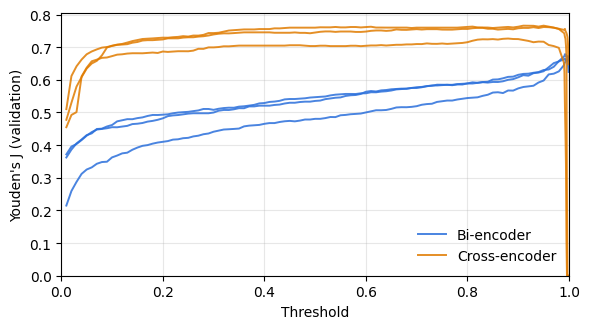

,Threshold (validation),"J drop, thresholds 0.16–0.977 (validation)",Non-identical found,Look-alike rejected,"AUC, non-identical vs look-alike"
Bi-encoder,0.992–0.999,0.166–0.221,70.2–78.1,86.7–93.4,0.883–0.893
Cross-encoder,0.880–0.949,0.041–0.045,77.7–78.6,90.1–92.2,0.888–0.904


,best J (validation)
Bi-encoder,0.665–0.680
Cross-encoder,0.728–0.768


In [25]:
from sklearn.metrics import roc_curve

v_nonid, v_look = masks["val"]["Non-identical found"], masks["val"]["Look-alike rejected"]
grid = np.r_[np.linspace(0.01, 0.99, 99), np.linspace(0.991, 0.999, 9)]
band = (grid >= 0.16) & (grid <= 0.977)


def youden_curve(probs):
    """J at every threshold of grid: share of non-identical matches at or above t − share of look-alike streets at or above t."""
    return np.array([(probs[v_nonid] >= t).mean() - (probs[v_look] >= t).mean() for t in grid])


fig, ax = plt.subplots(figsize=(6, 3.4))
for name, colour in zip(BERT, ["#2a6fdb", "#e07b00"]):
    for s, pv in zip(SEEDS, bert[name]["val"]):
        ax.plot(grid, youden_curve(pv), color=colour, lw=1.4, alpha=0.85, label=name if s == 0 else None)
ax.set_xlabel("Threshold")
ax.set_ylabel("Youden's J (validation)")
ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
for ext in ["pdf", "svg"]:
    fig.savefig(os.path.join(FIGURES, f"figure3_youden.{ext}"), bbox_inches="tight")
plt.show()

table14, best_j = {}, {}
for name in BERT:
    rows = []
    for pv, pt in zip(bert[name]["val"], bert[name]["test"]):
        m = v_nonid | v_look
        fpr, tpr, th = roc_curve(v_nonid[m], pv[m])
        t = th[np.argmax(tpr - fpr)]
        jg = youden_curve(pv)[band]
        rows.append({"Threshold (validation)": t, "J drop, thresholds 0.16–0.977 (validation)": jg.max() - jg.min(),
                     "Non-identical found": 100 * (pt[nonid] >= t).mean(),
                     "Look-alike rejected": 100 * (pt[look] < t).mean(),
                     AUC_COL: auc_vs(pt, nonid, look), "best J (validation)": (tpr - fpr).max()})
    frame = pd.DataFrame(rows)
    table14[name] = {c: fmt_range(frame[c], 1 if c in ("Non-identical found", "Look-alike rejected") else 3) for c in frame.columns}
table14 = pd.DataFrame(table14).T
display(table14.drop(columns="best J (validation)"))
table14[["best J (validation)"]]

### Table 15: the kept model of every family (test, %; neural models min–max over three seeds)

In [26]:
type_table({"XGBoost (sentinel)": KEPT["XGBoost"], "Siamese BiLSTM, mean pooling (3 seeds)": KEPT["Siamese BiLSTM"],
            "ESIM, fastText": KEPT["ESIM (fastText)"], "DistilBERT bi-encoder": KEPT["Bi-encoder"],
            "DistilBERT cross-encoder": KEPT["Cross-encoder"]})

,Identical found,Non-identical found,Different number rejected,Look-alike rejected,Random rejected,"AUC, non-identical vs look-alike"
XGBoost (sentinel),100.0,83.6,100.0,87.0,99.9,0.920
"Siamese BiLSTM, mean pooling (3 seeds)",100.0,87.0–89.3,99.9–100.0,69.8–73.1,99.5–99.8,0.878–0.893
"ESIM, fastText",100.0,87.3–90.3,98.1–99.0,73.5–80.4,99.8–99.9,0.861–0.890
DistilBERT bi-encoder,100.0,89.0–90.9,99.8–99.9,57.6–68.8,99.8–99.9,0.883–0.893
DistilBERT cross-encoder,100.0,80.3–83.0,99.9–100.0,86.1–88.8,99.9,0.888–0.904


## 6. Appendix B: the earlier version against this one
### Table B1: matches with a house number on one side only, % found at 0.5 (test, 164 pairs; min–max over three seeds)
Earlier version: `results/v1_missing_number_matches.csv`, computed from the v1 pairs and saved predictions (commit `7be57d6`) before they were removed. As in v1, the siamese BiLSTM is seed 0 only.

In [27]:
v1 = pd.read_csv("v1_missing_number_matches.csv", comment="#")
found = lambda probs: [missing_row(p)["Matches found (%)"] for p in probs]
B1 = {   # paper row -> (v1 model name, this version's test probabilities per seed)
    "XGBoost": ("XGBoost", KEPT["XGBoost"]),
    "Siamese BiLSTM, mean pooling (seed 0)": ("Siamese BiLSTM, mean pooling", KEPT["Siamese BiLSTM"][:1]),
    "ESIM, fastText": ("ESIM, fastText", KEPT["ESIM (fastText)"]),
    "DistilBERT bi-encoder": ("DistilBERT bi-encoder", KEPT["Bi-encoder"]),
    "DistilBERT cross-encoder": ("DistilBERT cross-encoder", KEPT["Cross-encoder"]),
}
pd.DataFrame({row: {"Earlier version": fmt_range(v1.loc[v1["model"] == old, "missing_number_matches_found_pct"]),
                    "This version": fmt_range(found(probs))} for row, (old, probs) in B1.items()}).T

,Earlier version,This version
XGBoost,22.6,94.5
"Siamese BiLSTM, mean pooling (seed 0)",32.9,69.5
"ESIM, fastText",12.8–14.0,71.3–75.6
DistilBERT bi-encoder,29.3–36.0,69.5–72.6
DistilBERT cross-encoder,13.4–19.5,63.4–66.5


## 7. Numbers quoted in the Discussion
Missing-number matches found at 0.5 (Table 4's 164 pairs) against all non-identical matches found, every neural model and every ESIM setting (test).

In [28]:
neural = {"Siamese BiLSTM, mean": siamese["mean"]["test"], "Siamese BiLSTM, max": siamese["max"]["test"],
          **{f"ESIM, {name}": esim[run]["test"] for name, run in ESIM.items()},
          "DistilBERT bi-encoder": bert["Bi-encoder"]["test"], "DistilBERT cross-encoder": bert["Cross-encoder"]["test"]}
rows = {}
for name, probs in neural.items():
    miss = found(probs)
    overall = [type_row(p, "test")["Non-identical found"] for p in probs]
    rows[name] = {"Missing-number matches found": fmt_range(miss), "Non-identical found": fmt_range(overall),
                  "Gap (points)": fmt_range([o - m for o, m in zip(overall, miss)])}
display(pd.DataFrame(rows).T)
kept = ["Siamese BiLSTM, mean", "ESIM, fastText, min_count 1", "DistilBERT bi-encoder", "DistilBERT cross-encoder"]
all_esim = [v for name, probs in neural.items() if name.startswith("ESIM") for v in found(probs)]
print("kept neural models, missing-number matches found:", fmt_range([v for k in kept for v in found(neural[k])]))
print("all five ESIM settings:", fmt_range(all_esim))
print("tree models (sentinel):", fmt_range([pct_correct(classical[m]["test"][0], "test", m_match["test"]) for m in ["RF sentinel", "XGB sentinel"]]))

,Missing-number matches found,Non-identical found,Gap (points)
"Siamese BiLSTM, mean",69.5–75.6,87.0–89.3,13.7–17.7
"Siamese BiLSTM, max",68.3–70.7,84.2–85.3,14.6–15.9
"ESIM, word2vec, min_count 2 (reproduction)",72.6–74.4,87.2–88.4,14.0–15.3
"ESIM, word2vec, min_count 1",63.4–72.6,84.9–87.8,14.9–21.5
"ESIM, fastText, min_count 1",71.3–75.6,87.3–90.3,14.1–17.3
"ESIM, Random vector per rare word",63.4–71.3,85.4–88.0,16.7–22.0
"ESIM, word2vec + fastText stacked",72.6–75.0,85.1–89.0,12.5–14.0
DistilBERT bi-encoder,69.5–72.6,89.0–90.9,18.3–19.5
DistilBERT cross-encoder,63.4–66.5,80.3–83.0,14.9–16.9


kept neural models, missing-number matches found: 63.4–75.6
all five ESIM settings: 63.4–75.6
tree models (sentinel): 94.5–96.3
